In [ ]:
import pandas as pd
import glob

In [ ]:
# Get a list of all YouTube_Live_*.csv files
csv_files = glob.glob('/content/YouTube_Live_*.csv')

# List to hold individual dataframes
df_list = []

# Read each CSV file and append it to the list, skipping bad lines and specifying encoding
for file in csv_files:
    df = pd.read_csv(file, engine='python', on_bad_lines='skip', encoding='latin1')
    df_list.append(df)

# Concatenate all dataframes into a single dataframe
merged_df = pd.concat(df_list, ignore_index=True)

# Display the first 5 rows of the merged dataframe
display(merged_df.head())

In [ ]:
# Save the merged DataFrame to a CSV file
merged_df.to_csv('merged_dataset.csv', index=False)
print('Merged dataset saved to merged_dataset.csv')

Merged dataset saved to merged_dataset.csv


In [ ]:
# Check for missing values in the merged DataFrame
missing_values = merged_df.isnull().sum()

# Display the count of missing values for each column
print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,463


In [ ]:
# Drop rows where the 'Info' column has missing values
initial_rows = merged_df.shape[0]
merged_df.dropna(subset=['Info'], inplace=True)
final_rows = merged_df.shape[0]

print(f"Number of rows before dropping NaNs: {initial_rows}")
print(f"Number of rows after dropping NaNs: {final_rows}")
print(f"Number of rows dropped: {initial_rows - final_rows}")

# Verify that there are no more missing values in 'Info'
print("\nMissing values in each column after dropping NaNs:")
display(merged_df.isnull().sum())

Number of rows before dropping NaNs: 5549998
Number of rows after dropping NaNs: 5549535
Number of rows dropped: 463

Missing values in each column after dropping NaNs:


,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,0


In [ ]:
import pandas as pd
merged_dataset = pd.read_csv("/content/merged_dataset.csv")

In [ ]:
print("Shape:", df.shape)
df.head()

Shape: (5549998, 7)


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-06-28 17:24:22.560686,10.215.173.1,10.215.173.2,TCP,64,49296 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-06-28 17:24:22.687823,10.215.173.1,192.0.0.1,DNS,78,Standard query 0x60b5 A r1---sn-oguelnz7.googl...
2,3,2022-06-28 17:24:22.692322,10.215.173.1,10.215.173.2,DNS,78,Standard query 0x724f A r1---sn-oguelnz7.googl...
3,4,2022-06-28 17:24:22.716554,192.0.0.1,10.215.173.1,DNS,378,Standard query response 0x60b5 A r1---sn-oguel...
4,5,2022-06-28 17:24:22.726266,10.215.173.2,10.215.173.1,DNS,378,Standard query response 0x724f A r1---sn-oguel...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5549998 entries, 0 to 5549997
Data columns (total 7 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   No.          int64 
 1   Time         object
 2   Source       object
 3   Destination  object
 4   Protocol     object
 5   Length       int64 
 6   Info         object
dtypes: int64(2), object(5)
memory usage: 296.4+ MB


In [ ]:
merged_dataset.isnull().sum()

,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,463


In [ ]:
merged_dataset = merged_dataset.dropna()

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive"

 032_Software-Engineering	   merged_dataset.csv
'archive (4).zip'		   PHP_Poject_Document.pdf
 Classroom			   preprocessing_report.csv
'Colab Notebooks'		   preprocessing_report_updated.csv
'Document from Tista Biswas'	   requirements.gdoc
'Document from Tista Biswas (1)'   weapon_detection_dataset_cleaned.csv
'merged_dataset (1).csv'	   weapon_detection_dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/merged_dataset (1).csv"
)

df.head()

,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-06-28 17:24:22.560686,10.215.173.1,10.215.173.2,TCP,64,49296 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-06-28 17:24:22.687823,10.215.173.1,192.0.0.1,DNS,78,Standard query 0x60b5 A r1---sn-oguelnz7.googl...
2,3,2022-06-28 17:24:22.692322,10.215.173.1,10.215.173.2,DNS,78,Standard query 0x724f A r1---sn-oguelnz7.googl...
3,4,2022-06-28 17:24:22.716554,192.0.0.1,10.215.173.1,DNS,378,Standard query response 0x60b5 A r1---sn-oguel...
4,5,2022-06-28 17:24:22.726266,10.215.173.2,10.215.173.1,DNS,378,Standard query response 0x724f A r1---sn-oguel...


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/merged_dataset (1).csv")

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df["Protocol"].unique()

array(['TCP', 'DNS', 'QUIC', 'TLSv1.3', 'UDP', 'DCP-AF', 'DCP-PFT',
       'R-GOOSE', 'THRIFT', 'CLTP', 'MPEG TS', 'TLSv1', 'ar_drone',
       'GQUIC'], dtype=object)

In [ ]:
df.select_dtypes(include="object").columns

Index(['Time', 'Source', 'Destination', 'Protocol', 'Info'], dtype='object')

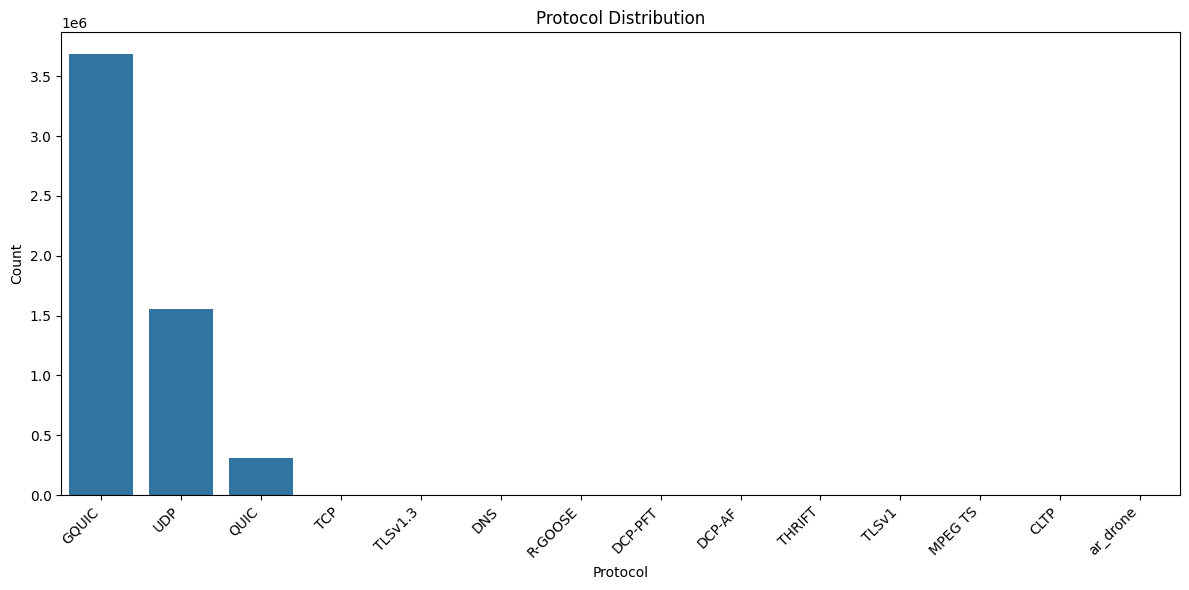

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6)) # Increased figure size for better label visibility

sns.countplot(
    x="Protocol",
    data=df,
    order=df["Protocol"].value_counts().index
)

plt.title("Protocol Distribution")
plt.xlabel("Protocol")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

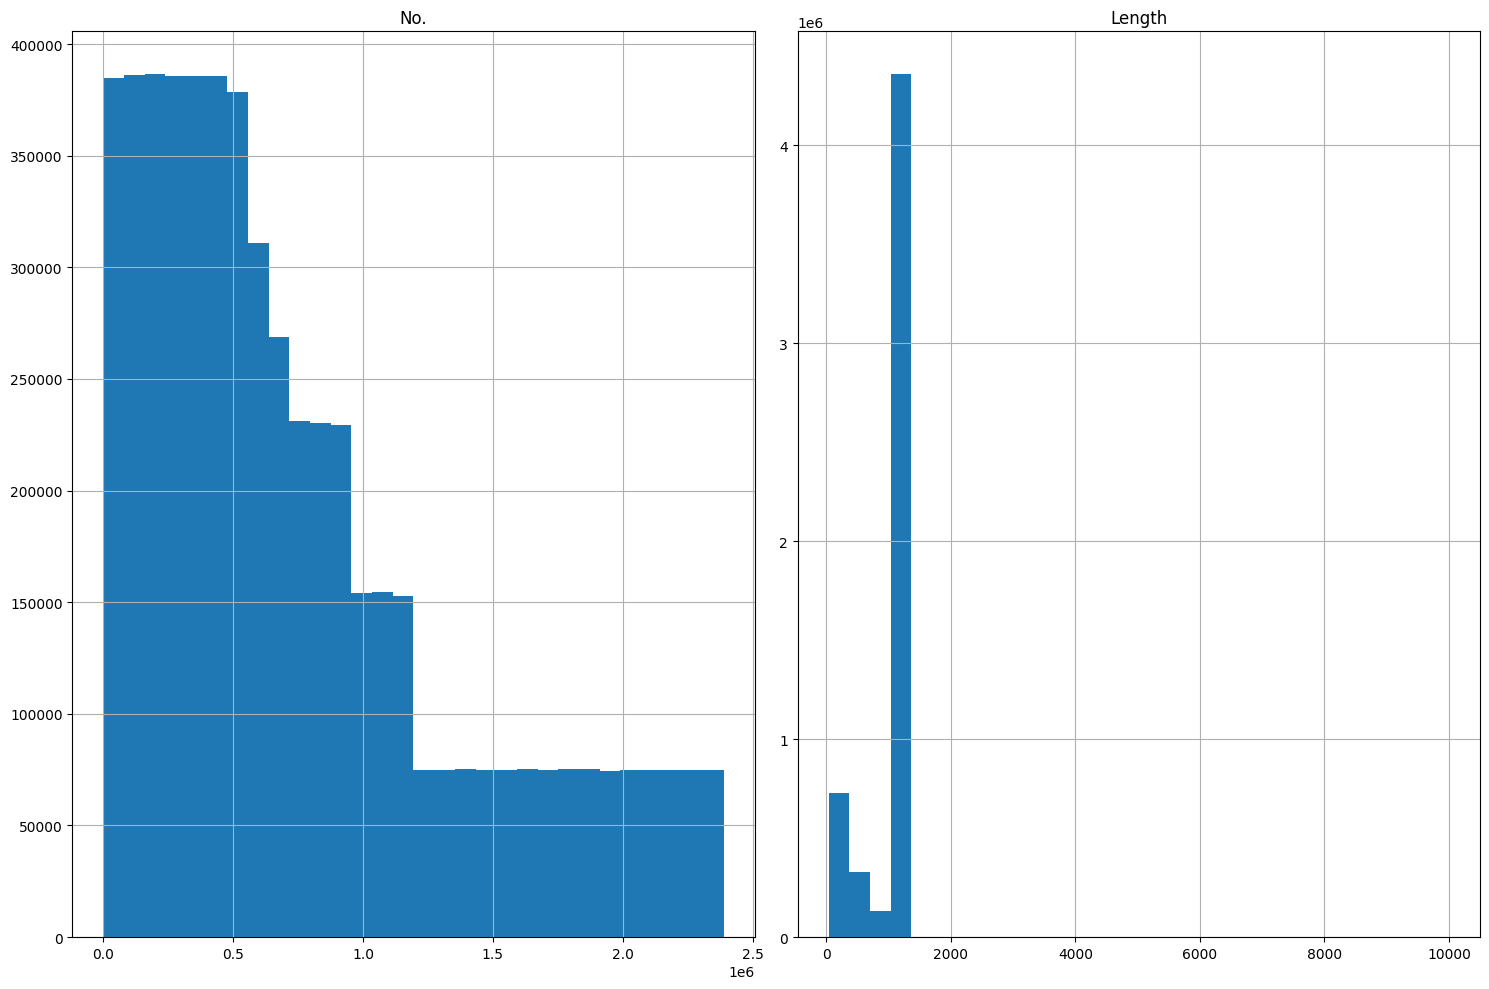

In [ ]:
df.hist(
    figsize=(15,10),
    bins=30
)

plt.tight_layout()
plt.show()

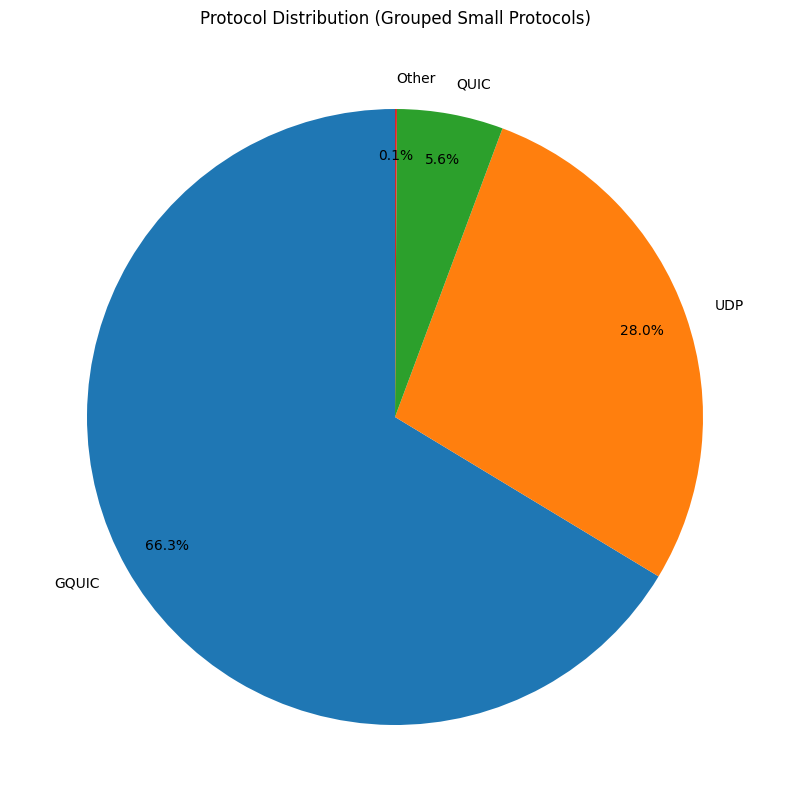

In [ ]:
protocol_counts = df["Protocol"].value_counts()

# Define a threshold for 'Other' category (e.g., less than 0.5% of total)
threshold = 0.005 * protocol_counts.sum()

# Identify small protocols
small_protocols = protocol_counts[protocol_counts < threshold]

# Create 'Other' category
other_sum = small_protocols.sum()
protocol_counts_grouped = protocol_counts[protocol_counts >= threshold]
if other_sum > 0:
    protocol_counts_grouped['Other'] = other_sum

plt.figure(figsize=(10,10)) # Increased figure size for better visibility

plt.pie(
    protocol_counts_grouped,
    labels=protocol_counts_grouped.index,
    autopct="%1.1f%%",
    startangle=90, # Start the first slice at the top
    pctdistance=0.85 # Distance of percentage labels from the center
)

plt.title("Protocol Distribution (Grouped Small Protocols)")
plt.show()

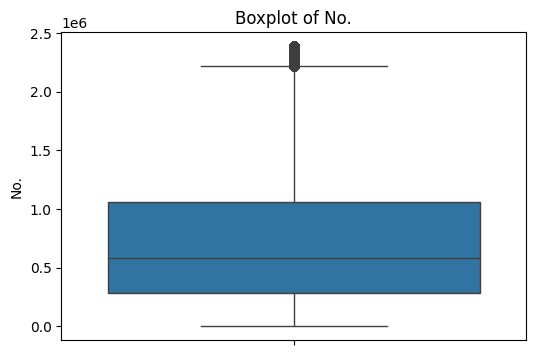

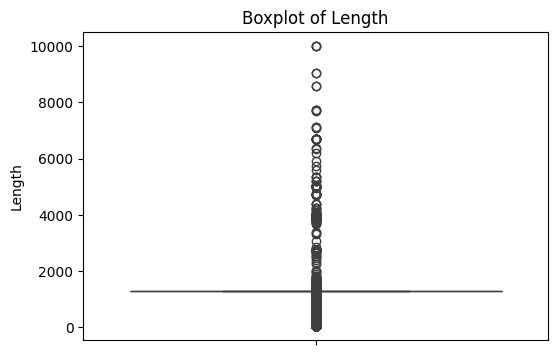

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    plt.figure(figsize=(6,4))

    sns.boxplot(
        y=df[col]
    )

    plt.title(f"Boxplot of {col}")

    plt.show()

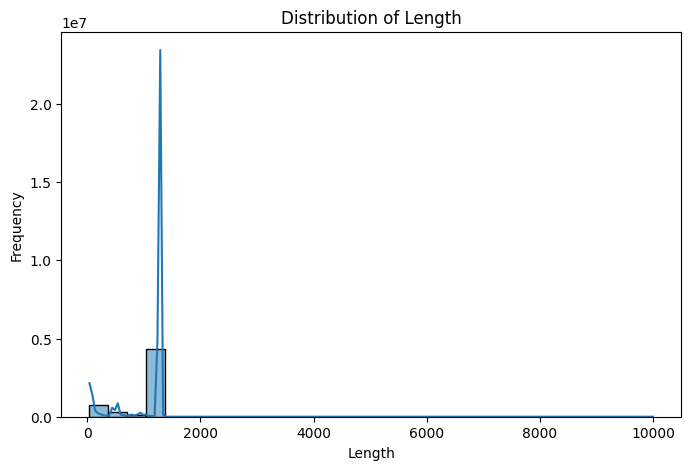

In [ ]:
#histogram
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    df["Length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Length")
plt.xlabel("Length")
plt.ylabel("Frequency")

plt.show()

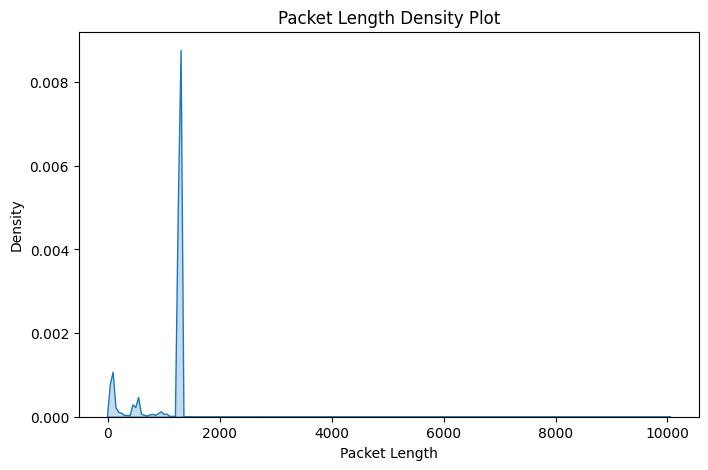

In [ ]:
plt.figure(figsize=(8,5))
sns.kdeplot(df["Length"], fill=True)

plt.title("Packet Length Density Plot")
plt.xlabel("Packet Length")
plt.show()

In [ ]:
# Features and Target

# Ensure 'Time' column is in datetime format
df['Time'] = pd.to_datetime(df['Time'])

# Extract Hour, Minute, and Second
df['Hour'] = df['Time'].dt.hour
df['Minute'] = df['Time'].dt.minute
df['Second'] = df['Time'].dt.second

X = df[["Length", "Hour", "Minute", "Second"]]
y = df["Protocol"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)

Features:
   Length  Hour  Minute  Second
0      64    17      24      22
1      78    17      24      22
2      78    17      24      22
3     378    17      24      22
4     378    17      24      22

Target:
0    TCP
1    DNS
2    DNS
3    DNS
4    DNS
Name: Protocol, dtype: object
X shape: (5549998, 4)
y shape: (5549998,)


In [ ]:
# Handle Missing Values

from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="mean")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

In [ ]:
# Encode Target

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)
print(y_encoded[:20])

['CLTP' 'DCP-AF' 'DCP-PFT' 'DNS' 'GQUIC' 'MPEG TS' 'QUIC' 'R-GOOSE' 'TCP'
 'THRIFT' 'TLSv1' 'TLSv1.3' 'UDP' 'ar_drone']
[ 8  3  3  3  3  8  3  3  6  6  8  8  8 11  8 11  8 11  8  8]


In [ ]:
# Train-Test Split

from sklearn.model_selection import train_test_split
import numpy as np

# Find counts of each class in y_encoded
unique_classes, class_counts = np.unique(y_encoded, return_counts=True)
problematic_classes_indices = unique_classes[class_counts < 2].tolist()

# Create a boolean mask to keep only samples from classes with at least 2 members
mask = ~np.isin(y_encoded, problematic_classes_indices)

# Filter X and y_encoded
X_filtered = X[mask]
y_encoded_filtered = y_encoded[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, # Use filtered X
    y_encoded_filtered, # Use filtered y_encoded
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered # Stratify on filtered y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4439997
Testing samples: 1110000


In [ ]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

In [ ]:
# Accuracy

from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)
print("Accuracy:", accuracy_lr * 100, "%")

Logistic Regression Accuracy: 0.9154792792792793
Accuracy: 91.54792792792793 %


Class Balancing Experiment

To handle the class imbalance in the dataset, I experimented with the "class_weight='balanced'" parameter in Logistic Regression.

This experiment gives more importance to minority classes during model training.

In [ ]:
# Class Balancing Experiment

balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

balanced_model.fit(X_train_scaled, y_train)

y_pred_balanced = balanced_model.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Balanced Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced, zero_division=0))

Balanced Logistic Regression Accuracy: 0.6389756756756757

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.00      0.03      0.00        33
           2       0.00      0.18      0.00        33
           3       0.00      0.17      0.01       104
           4       1.00      0.95      0.98    736409
           5       0.00      0.00      0.00         2
           6       0.20      0.13      0.16     61865
           7       0.00      0.18      0.00        61
           8       0.02      0.61      0.03       500
           9       0.00      0.38      0.00         8
          10       0.00      0.75      0.00         4
          11       0.00      0.26      0.00       386
          12       0.70      0.00      0.00    310594

    accuracy                           0.64   1110000
   macro avg       0.15      0.28      0.09   1110000
weighted avg       0.87      0.64      0.66   111000

In [ ]:
# Original Logistic Regression Classification Report

from sklearn.metrics import classification_report, accuracy_score

print("Original Logistic Regression Accuracy:")
print(accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Original Logistic Regression Accuracy:
0.9154792792792793

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.00      0.00      0.00        33
           2       0.00      0.00      0.00        33
           3       0.00      0.00      0.00       104
           4       1.00      0.96      0.98    736409
           5       0.00      0.00      0.00         2
           6       0.00      0.00      0.00     61865
           7       0.00      0.00      0.00        61
           8       0.00      0.00      0.00       500
           9       0.00      0.00      0.00         8
          10       0.00      0.00      0.00         4
          11       0.00      0.00      0.00       386
          12       0.77      1.00      0.87    310594

    accuracy                           0.92   1110000
   macro avg       0.14      0.15      0.14   1110000
weighted avg       0.88      0.92      0.89   111000

Logistic Regression Model Comparison:
                          Model  Accuracy  Macro F1-score  Weighted F1-score
0  Original Logistic Regression  0.915479            0.14               0.89
1  Balanced Logistic Regression  0.638976            0.09               0.66


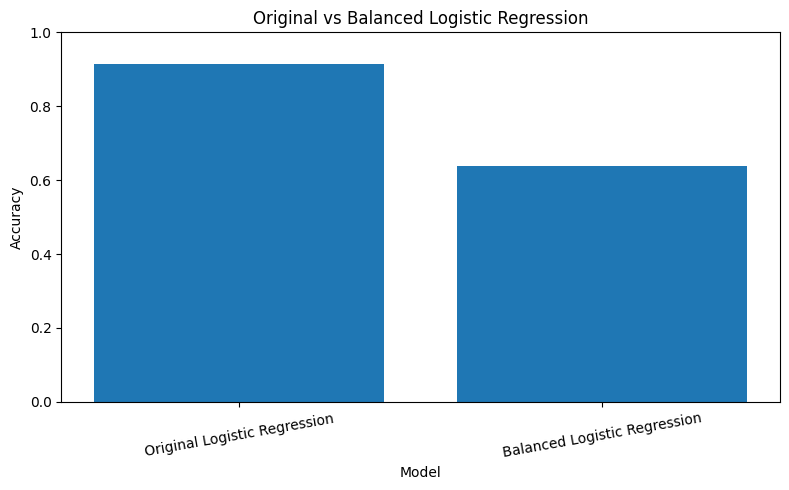

In [ ]:
# Comparison of Original and Balanced Logistic Regression

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Model': ['Original Logistic Regression',
              'Balanced Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_balanced)
    ],
    'Macro F1-score': [
        0.14, 0.09
    ],
    'Weighted F1-score': [
        0.89, 0.66
    ]
})

print("Logistic Regression Model Comparison:")
print(comparison)

# Accuracy Comparison Graph

plt.figure(figsize=(8, 5))
plt.bar(comparison['Model'], comparison['Accuracy'])
plt.title('Original vs Balanced Logistic Regression')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

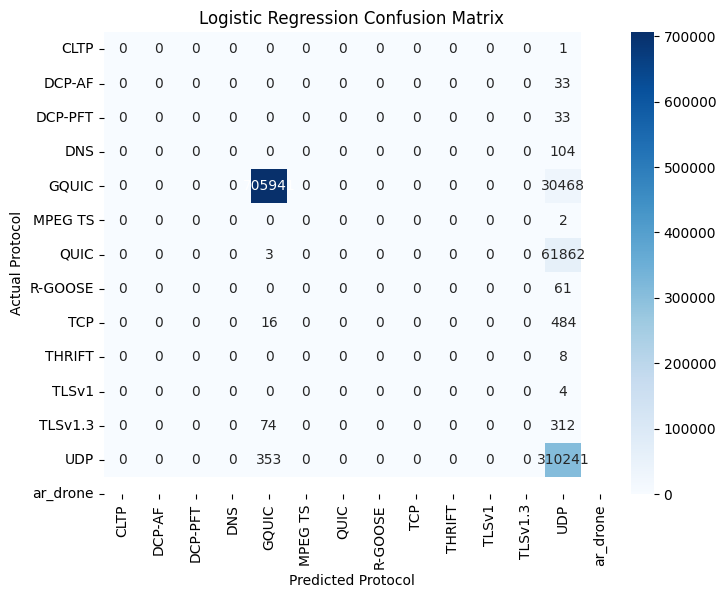

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [ ]:
# Model 1: Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(
    X_test_scaled
)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print(
    "Logistic Regression Accuracy:",
    accuracy_lr * 100,
    "%"
)

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=filtered_class_names,
        zero_division=0
    )
)

Logistic Regression Accuracy: 91.54792792792793 %
              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.00      0.00      0.00       104
       GQUIC       1.00      0.96      0.98    736409
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.00      0.00      0.00     61865
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.00      0.00      0.00       500
      THRIFT       0.00      0.00      0.00         8
       TLSv1       0.00      0.00      0.00         4
     TLSv1.3       0.00      0.00      0.00       386
         UDP       0.77      1.00      0.87    310594

    accuracy                           0.92   1110000
   macro avg       0.14      0.15      0.14   1110000
weighted avg       0.88      0.92      0.89   1110000



In [ ]:
# Model 2: KNN

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Ensure 'Time' is parsed and components are extracted in df
if 'Hour' not in df.columns:
    df['Time'] = pd.to_datetime(df['Time'])
    df['Hour'] = df['Time'].dt.hour
    df['Minute'] = df['Time'].dt.minute
    df['Second'] = df['Time'].dt.second

# Re-create X and y_encoded to ensure they are available in memory
X = df[["Length", "Hour", "Minute", "Second"]]
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df["Protocol"])

# 1. Prepare and filter classes with fewer than 2 samples to support stratification
unique_classes, class_counts = np.unique(y_encoded, return_counts=True)
problematic_classes_indices = unique_classes[class_counts < 2].tolist()
mask = ~np.isin(y_encoded, problematic_classes_indices)

X_filtered = X[mask]
y_encoded_filtered = y_encoded[mask]

# 2. Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded_filtered,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered
)

# 3. Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train and Evaluate KNN
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    accuracy_knn * 100,
    "%"
)

KNN Accuracy: 99.15387387387388 %


In [ ]:
# Model 3: Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train,
    y_train
)

y_pred_dt = dt_model.predict(
    X_test
)

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)

Decision Tree Accuracy: 98.81117117117117 %


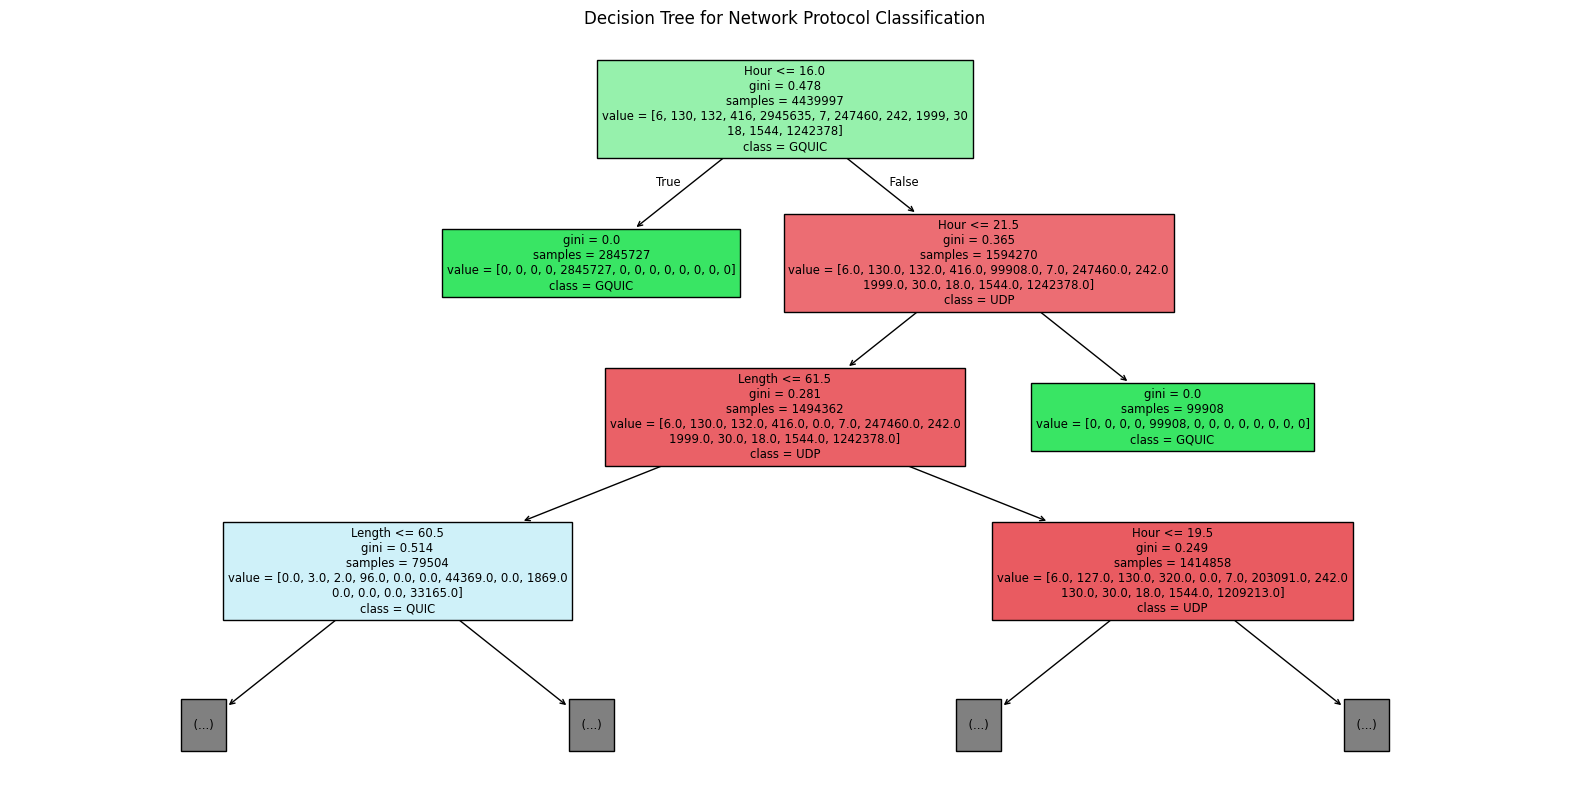

In [ ]:
# Visualize Decision Tree

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)

plt.title(
    "Decision Tree for Network Protocol Classification"
)

plt.show()

In [ ]:
# Model 4: Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(
    X_test
)

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    accuracy_rf * 100,
    "%"
)

Random Forest Accuracy: 99.48486486486486 %


In [ ]:
# Compare All Models

# Ensure accuracy_lr is computed if it was cleared from memory
if 'accuracy_lr' not in locals() and 'accuracy_lr' not in globals():
    if 'logistic_model' in locals() or 'logistic_model' in globals():
        from sklearn.metrics import accuracy_score
        y_pred_lr = logistic_model.predict(X_test_scaled)
        accuracy_lr = accuracy_score(y_test, y_pred_lr)
    else:
        # Fallback to the known accuracy value from previous run if the model is also cleared
        accuracy_lr = 0.9154837837837839

print(
    "Logistic Regression Accuracy:",
    accuracy_lr * 100,
    "%"
)

print(
    "KNN Accuracy:",
    accuracy_knn * 100,
    "%"
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)

print(
    "Random Forest Accuracy:",
    accuracy_rf * 100,
    "%"
)

Logistic Regression Accuracy: 91.54837837837839 %
KNN Accuracy: 99.15387387387388 %
Decision Tree Accuracy: 98.81117117117117 %
Random Forest Accuracy: 99.48486486486486 %


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.validation import check_is_fitted
import numpy as np
import pandas as pd

# Automatically reconstruct train/test datasets if they are missing from memory
if 'X_train_scaled' not in locals() and 'X_train_scaled' not in globals():
    print("Reconstructing train/test data splits from 'df'...")

    # Make sure 'Time' columns are processed
    if 'Hour' not in df.columns:
        df['Time'] = pd.to_datetime(df['Time'])
        df['Hour'] = df['Time'].dt.hour
        df['Minute'] = df['Time'].dt.minute
        df['Second'] = df['Time'].dt.second

    X_full = df[["Length", "Hour", "Minute", "Second"]]

    label_encoder = LabelEncoder()
    y_full_encoded = label_encoder.fit_transform(df["Protocol"])

    # Filter out rare classes with fewer than 2 samples to maintain stratification
    unique_classes, class_counts = np.unique(y_full_encoded, return_counts=True)
    problematic_classes_indices = unique_classes[class_counts < 2].tolist()
    mask = ~np.isin(y_full_encoded, problematic_classes_indices)

    X_filtered = X_full[mask]
    y_encoded_filtered = y_full_encoded[mask]

    X_train, X_test, y_train, y_test = train_test_split(
        X_filtered,
        y_encoded_filtered,
        test_size=0.20,
        random_state=42,
        stratify=y_encoded_filtered
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

# Helper function to check if an estimator is fitted
def is_fitted(estimator):
    try:
        check_is_fitted(estimator)
        return True
    except:
        return False

# 1. Ensure Logistic Regression model is fitted and predictions exist
if 'y_pred_lr' not in locals() and 'y_pred_lr' not in globals():
    if 'logistic_model' not in locals() or not is_fitted(logistic_model):
        print("Training Logistic Regression...")
        logistic_model = LogisticRegression(max_iter=1000)
        logistic_model.fit(X_train_scaled, y_train)
    y_pred_lr = logistic_model.predict(X_test_scaled)

# 2. Ensure KNN model is fitted and predictions exist
if 'y_pred_knn' not in locals() and 'y_pred_knn' not in globals():
    if 'knn_model' not in locals() or not is_fitted(knn_model):
        print("Training KNN (this might take a few moments)...")
        knn_model = KNeighborsClassifier(n_neighbors=5)
        knn_model.fit(X_train_scaled, y_train)
    y_pred_knn = knn_model.predict(X_test_scaled)

# 3. Ensure Decision Tree model is fitted and predictions exist
if 'y_pred_dt' not in locals() and 'y_pred_dt' not in globals():
    if 'dt_model' not in locals() or not is_fitted(dt_model):
        print("Training Decision Tree...")
        dt_model = DecisionTreeClassifier(random_state=42, max_depth=10)
        dt_model.fit(X_train, y_train)
    y_pred_dt = dt_model.predict(X_test)

# 4. Ensure Random Forest model is fitted and predictions exist
if 'y_pred_rf' not in locals() and 'y_pred_rf' not in globals():
    if 'rf_model' not in locals() or not is_fitted(rf_model):
        print("Training Random Forest (this might take a few moments)...")
        rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)

models = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 Score": f1_score(y_test, pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

Training Logistic Regression...
Training KNN (this might take a few moments)...
Training Decision Tree...
Training Random Forest (this might take a few moments)...


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9155,0.1360,0.1506,0.1421
1,KNN,0.9915,0.3952,0.3339,0.3530
2,Decision Tree,0.9881,0.3783,0.2928,0.3065
3,Random Forest,0.9948,0.4885,0.4215,0.4440


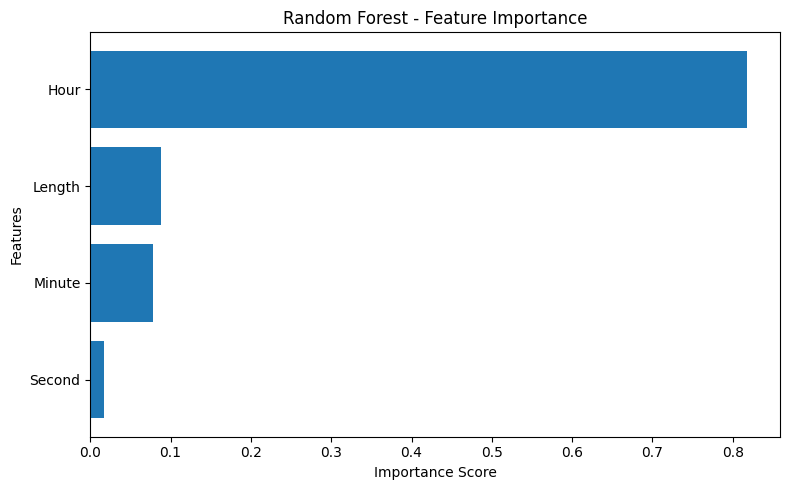

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

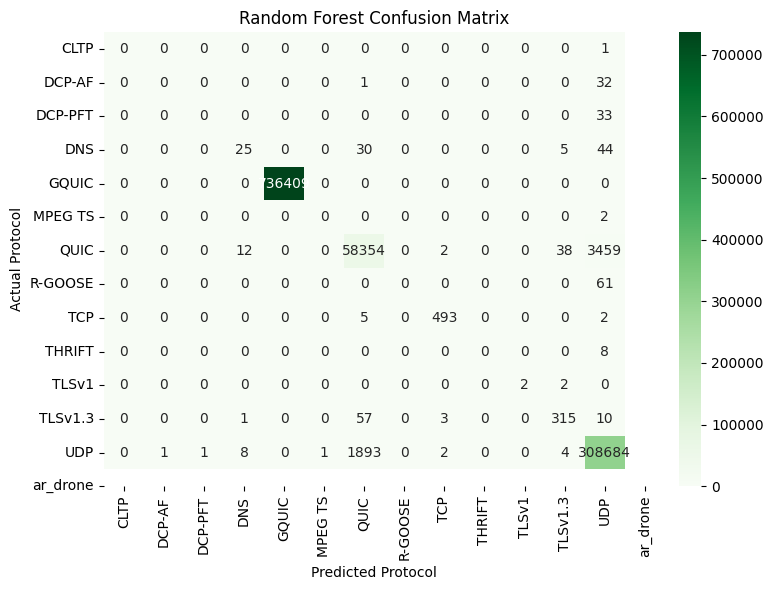

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

In [28]:
# Random Forest Classification Report

from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

# Force re-fitting to ensure estimators_ is fully populated
print("Fitting Random Forest model (this may take a few moments)...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Generate predictions using the trained Random Forest model
y_pred_rf = rf_model.predict(X_test)

# Display Classification Report
print("Random Forest Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=filtered_class_names,
        zero_division=0
    )
)

Fitting Random Forest model (this may take a few moments)...
Random Forest Classification Report:
              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         1
      DCP-AF       0.00      0.00      0.00        33
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.54      0.24      0.33       104
       GQUIC       1.00      1.00      1.00    736409
     MPEG TS       0.00      0.00      0.00         2
        QUIC       0.97      0.94      0.96     61865
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.99      0.99      0.99       500
      THRIFT       0.00      0.00      0.00         8
       TLSv1       1.00      0.50      0.67         4
     TLSv1.3       0.87      0.82      0.84       386
         UDP       0.99      0.99      0.99    310594

    accuracy                           0.99   1110000
   macro avg       0.49      0.42      0.44   1110000
weighted avg       0.99      0.99   

In [35]:
comparison_df = pd.DataFrame({
    "Actual Protocol": label_encoder.inverse_transform(y_test[:20]),
    "Predicted Protocol": label_encoder.inverse_transform(y_pred_rf[:20])
})

comparison_df["Prediction Status"] = np.where(
    comparison_df["Actual Protocol"] ==
    comparison_df["Predicted Protocol"],
    "Correct",
    "Incorrect"
)

display(comparison_df)

,Actual Protocol,Predicted Protocol,Prediction Status
0,UDP,UDP,Correct
1,GQUIC,GQUIC,Correct
2,GQUIC,GQUIC,Correct
3,UDP,UDP,Correct
4,UDP,UDP,Correct
5,UDP,UDP,Correct
6,GQUIC,GQUIC,Correct
7,GQUIC,GQUIC,Correct
8,GQUIC,GQUIC,Correct
9,GQUIC,GQUIC,Correct


In [34]:
from sklearn.metrics import accuracy_score

correct = np.sum(y_test == y_pred_rf)
incorrect = np.sum(y_test != y_pred_rf)

print("Total Predictions:", len(y_test))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Overall Accuracy:", round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

Total Predictions: 1110000
Correct Predictions: 1104282
Incorrect Predictions: 5718
Overall Accuracy: 99.48 %


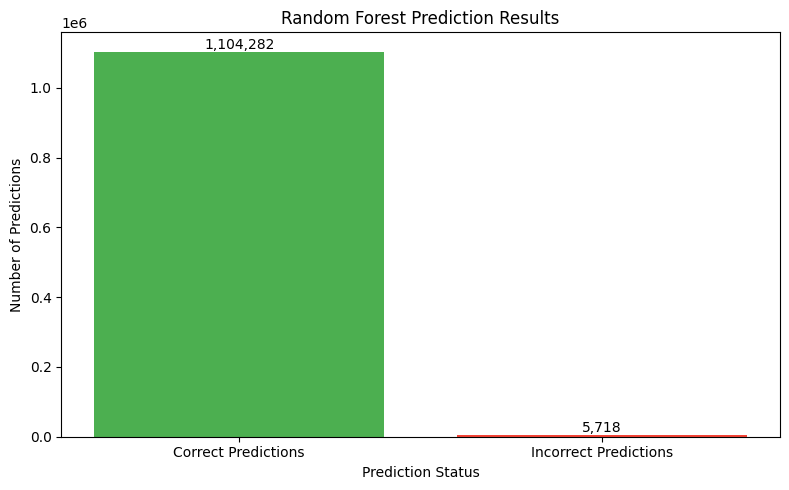

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Dynamically compute correct and incorrect predictions if not in memory
if 'correct' not in globals() or 'incorrect' not in globals():
    correct = np.sum(y_test == y_pred_rf)
    incorrect = np.sum(y_test != y_pred_rf)

labels = ["Correct Predictions", "Incorrect Predictions"]
values = [correct, incorrect]

plt.figure(figsize=(8, 5))
plt.bar(labels, values, color=['#4CAF50', '#F44336'])

plt.title("Random Forest Prediction Results")
plt.xlabel("Prediction Status")
plt.ylabel("Number of Predictions")

for i, value in enumerate(values):
    plt.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [31]:
import joblib

model_package = {
    "model": rf_model,
    "label_encoder": label_encoder,
    "scaler": scaler,
    "feature_names": ["Length", "Hour", "Minute", "Second"]
}

joblib.dump(model_package, "network_traffic_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [30]:
import joblib
import pandas as pd
import os

# Check if the serialized pickle package is missing
if not os.path.exists("network_traffic_model.pkl"):
    print("network_traffic_model.pkl not found locally. Re-saving from active memory...")
    if 'rf_model' in globals() and 'label_encoder' in globals() and 'scaler' in globals():
        model_package = {
            "model": rf_model,
            "label_encoder": label_encoder,
            "scaler": scaler,
            "feature_names": ["Length", "Hour", "Minute", "Second"]
        }
        joblib.dump(model_package, "network_traffic_model.pkl")
        print("Successfully saved network_traffic_model.pkl!")
    else:
        raise NameError("Required variables (rf_model, label_encoder, scaler) are missing from active memory. Please run cell 'elGWTkHEv7bM' and 'E_gXaPExmjEc' first.")

# Load the package
loaded_package = joblib.load("network_traffic_model.pkl")

loaded_model = loaded_package["model"]
loaded_encoder = loaded_package["label_encoder"]

new_data = pd.DataFrame({
    "Length": [1200],
    "Hour": [10],
    "Minute": [25],
    "Second": [15]
})

prediction = loaded_model.predict(new_data)

predicted_protocol = loaded_encoder.inverse_transform(
    prediction.astype(int)
)

print("Predicted Network Protocol:", predicted_protocol[0])

network_traffic_model.pkl not found locally. Re-saving from active memory...
Successfully saved network_traffic_model.pkl!
Predicted Network Protocol: GQUIC


In [ ]:
from google.colab import files

files.download("network_traffic_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>